# INF201 – Deliverable 1

## Introduction
This notebook contains Python code and explanations.

## G2_2 Filmon Tsegay Kahsay and Amin Elanbri
Link to github: https://github.com/filmonkah/INF201-Deliverable-1


In [35]:
from getpass import getpass
from pathlib import Path
from datetime import date

import matplotlib.pyplot as plt
import pandas as pd
import requests
import yaml

## Task 1: Temperature

In this task, we will retrive daily mean air temperature data from the Ås weather station for the year 2025. 

In [36]:
client_id = getpass("Enter your Frost Client ID: ")

In [37]:
endpoint = "https://frost.met.no/observations/v0.jsonld"

parameters = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)", 
    "referencetime": "2025-01-01/2026-01-01",
}

In [38]:
#Frost API request based on the approach shown in MET Norway's Phython exple.
response = requests.get(
    endpoint, 
    params=parameters, 
    auth=(client_id, "")
)

print(response.status_code)

200


In [39]:
data = response.json()


In [40]:
temperatures = []

# Extract one dauly mean temperature per date using the PT0H time offset.
for day in data["data"]:
    for observation in day["observations"]:
        if observation["timeOffset"] == "PT0H":
            temperatures.append({
                "date": day["referenceTime"], 
                "temperature": observation["value"]
            })



In [41]:
df = pd.DataFrame(temperatures)

df["date"] = pd.to_datetime(df["date"])

print("Number of days:", len(df))

Number of days: 365


In [42]:
# Calculate summary statistics for the daily mean temperatures.
mean_temp = df["temperature"].mean()
median_temp = df["temperature"].median()
min_temp = df["temperature"].min()
max_temp = df["temperature"].max()




In [43]:
print("Temperature summary - Ås, 2025")
print("-" *35)
print(f"{'Mean:':<12} {mean_temp:>8.2f} °C")
print(f"{'Median:':<12} {median_temp:>8.2f} °C")
print(f"{'Minimum:':<12} {min_temp:>8.2f} °C")
print(f"{'Maximum:':<12} {max_temp:>8.2f} °C")

Temperature summary - Ås, 2025
-----------------------------------
Mean:            7.87 °C
Median:          8.30 °C
Minimum:       -15.50 °C
Maximum:        23.70 °C


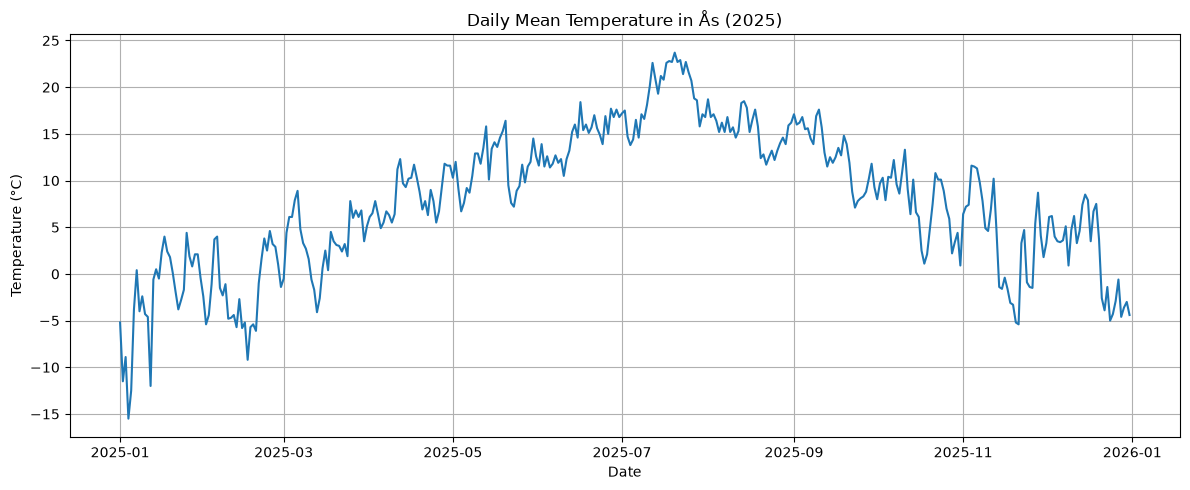

In [44]:
plt.figure(figsize=(12,5))

plt.plot(df["date"], df["temperature"])

plt.title("Daily Mean Temperature in Ås (2025)")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")

plt.grid(True)
plt.tight_layout()
plt.show()

## Results and discussion
We can see on the graph that the daily mean air temperature in Ås varies throughout 2025. The highest daily mean temperature was 23.7 °C and the lowest around -15.5°C, The temperature wa increasing when it was somer time, and starts to go down when it is on the way to  fall seson.
The median was 8.30 °C and the annual mean 7.87 °C.
In this analysis we used the PT0H time series, that represents the daily mean temperatures from midnight to midnight, following the preferred time offset in the Frost documentation (MET Norway, nd.). 


## Task 2: Precipitation
For this task daily precipitation data from Ås in 2025 are retrived from the Frost API and plotted together with daily mean temperature.

In [45]:
# Define the parameters for daily precipitation in 2025.
precip_parameters = {
    "sources": "SN17850",
    "elements": "sum(precipitation_amount P1D)",
    "referencetime": "2025-01-01/2026-01-01",
}

In [46]:
# Request daily precipitation data from the Frost API.
precip_response = requests.get(
    endpoint,
    params=precip_parameters,
    auth=(client_id, "")
)

print("Status code:", precip_response.status_code)

Status code: 200


In [47]:
precip_data = precip_response.json()


In [48]:
precipitation = []

# Select one consistent 24-hour precipitation series.
for day in precip_data["data"]:
    for observation in day["observations"]:
        if observation["timeOffset"] == "PT6H":
            precipitation.append({
                "date": day["referenceTime"], 
                "precipitation": observation["value"]
            })

In [49]:
precip_df = pd.DataFrame(precipitation)

precip_df["date"] = pd.to_datetime(precip_df["date"])

In [50]:
weather_df = pd.merge(
    df,
    precip_df,
    on="date",
    how="inner"
)

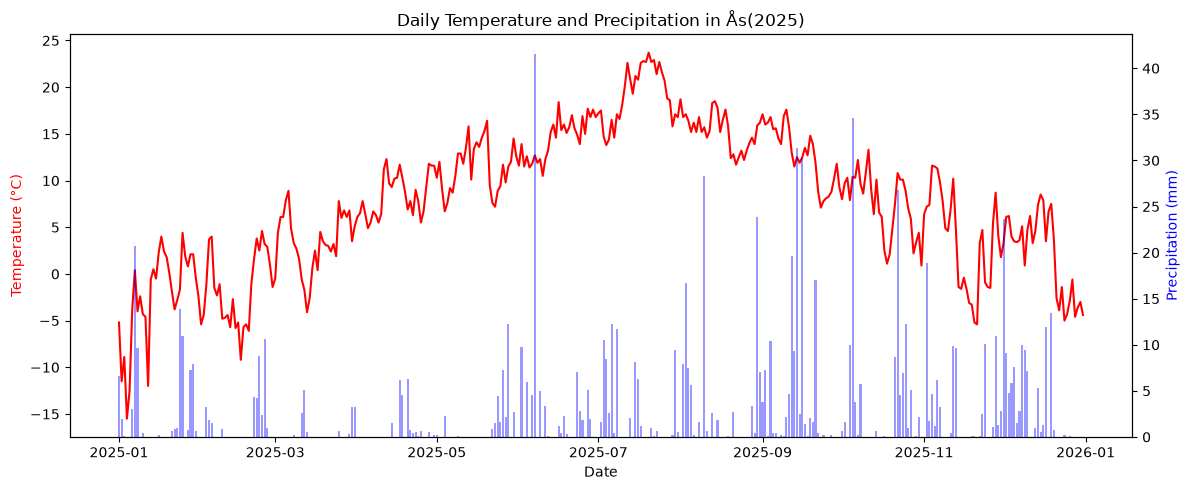

In [51]:
fig, ax1 = plt.subplots(figsize=(12, 5))

ax1.plot(weather_df["date"], weather_df["temperature"], color="red")
ax1.set_xlabel("Date")
ax1.set_ylabel("Temperature (°C)", color="red")

ax2 = ax1.twinx()

ax2.bar(
weather_df["date"],
weather_df["precipitation"],
color="blue",
alpha=0.4,
)
ax2.set_ylabel("Precipitation (mm)", color="blue")

plt.title("Daily Temperature and Precipitation in Ås(2025)")
fig.tight_layout()
plt.show()

## Results and discussion:
The graph above shows the daily mean temperature in Ås. We can see general increase from January to July, and from there gradually decreasing to the end of the year. 
For the precipitation there is no clear seasonal pattern as temperature, but we can see the highest daily preciptiation recorded is durning summer. Other thing we can see is several periods of precipitation durning the end of the year. We can therfor conclude that temperature follows a clear sesonal pattern, and preciptitation varies more irregulary throughout the year. 

PT0H time offset was used to select the temperature data, and PT6H for the precipitation data. These shold be considered when comparing the tew datasets, because they may represent different 24-hour periods. The PT6H time was selected becausee it was recommended in the Frost documentation (MET Norway, n.d.). 

## Task 3: Historical temperature data
In this task, we compare daily mean temperatures in Ås from 1925 and 2025, using data retrieved from the Frost API.


In [52]:
# Define the parameters for daily mean temperature in 1925.
historical_parameters = {
    "sources": "SN17850",
    "elements": "mean(air_temperature P1D)",
    "referencetime": "1925-01-01/1926-01-01",
}

In [53]:
# Request historical daily temperature data from the Frost API.
historical_response = requests.get(
    endpoint,
    params=historical_parameters,
    auth=(client_id, ""),
)

print("Status code:", historical_response.status_code)

Status code: 200


In [54]:
# Convert the API response to JSON.
historical_data = historical_response.json()

      

In [55]:
historical_temperatures = []

for day in historical_data["data"]:
    for observation in day["observations"]:
        if observation["timeOffset"] == "PT0H":
            historical_temperatures.append({
                "date": day["referenceTime"],
                "temperature": observation["value"]
            })

In [56]:
historical_df = pd.DataFrame(historical_temperatures)
historical_df["date"] = pd.to_datetime(historical_df["date"])




In [57]:
# Calculate summary statistics for the historical temperaturs.
historical_mean = historical_df["temperature"].mean()
historical_median = historical_df["temperature"].median()
historical_min = historical_df["temperature"].min()
historical_max = historical_df["temperature"].max()


In [58]:
# Compare summary statisticks for 1925 and 2025.
print(f"{'Statistic':<18}{'1925':>12}{'2025':>12}")
print("_" * 42)
print(f"{'Mean (°C)':<18} {historical_mean:>12.2f}{mean_temp:12.2f}")
print(f"{'Median (°C)':<18} {historical_median:>12.2f}{median_temp:12.2f}")
print(f"{'Min (°C)':<18} {historical_min:>12.2f}{min_temp:12.2f}")
print(f"{'Max (°C)':<18} {historical_max:>12.2f}{max_temp:12.2f}")

Statistic                 1925        2025
__________________________________________
Mean (°C)                  5.28        7.87
Median (°C)                5.30        8.30
Min (°C)                 -20.70      -15.50
Max (°C)                  24.30       23.70


In [59]:
# Creat a common day-of-year axis for both years.
df["day_of_year"] = df["date"].dt.dayofyear
historical_df["day_of_year"] = historical_df["date"].dt.dayofyear



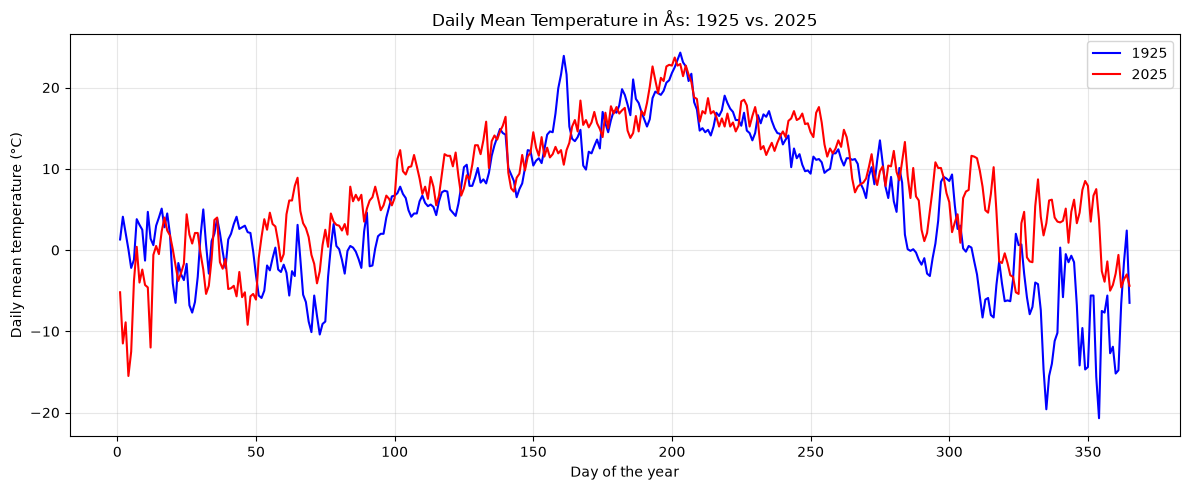

In [60]:
#Plot daily mean temperatures for 1925 and 2025.
plt.figure(figsize=(12, 5))

plt.plot(
    historical_df["day_of_year"],
    historical_df["temperature"],
    label="1925",
    color="blue",
)

plt.plot(
    df["day_of_year"],
    df["temperature"],
    label="2025",
    color="red",
)

plt.xlabel("Day of the year")
plt.ylabel("Daily mean temperature (°C)")
plt.title("Daily Mean Temperature in Ås: 1925 vs. 2025")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Results and discussion:
The graph and summary statistics show that 1925 had a lower average temperature than 2025. The mean temperature was 5.28 °C in 1925 and 7.87 °C in 2025, while the median temperatures were 5.30 °C and 8.30 °C, respectively.

The minimum temperature was −20.70 °C in 1925, compared with −15.50 °C in 2025. However, 1925 had a slightly higher maximum temperature of 24.30 °C, compared with 23.70 °C in 2025.

The graph also shows particularly low temperatures towards the end of 1925. Overall, 1925 had a wider temperature range, with both a lower minimum and a higher maximum temperature than 2025.

## Task 4: Heatwaves

In [61]:
def get_max_temperatures (
        station_id: str, year: int, client_id: str, time_offset: str
) -> list[dict[str, date | float]]:
    """Request daily max air temperature for a station and year form Frost. 

    Args: 
        station_id: Frost source ID
        year: The year request data for 
        client_id: Personal Frost client ID
        time_offset: Wich time series to use 

    Returns: 
        List with one dict per day, with keys "date" and "max_temperature". 
        The list is empty if the request fails 
    """
    parameters = { #what data we ask Frost for 
        "sources": station_id, #wich weather station 
        "elements": "max(air_temperature P1D)", #daily max temperature 
        "referencetime": f"{year}-01-01/{year + 1}-01-01", #the whole year 
    }
    response = requests.get(endpoint, params=parameters, auth=(client_id, ""))

    if response.status_code != 200: #checking if the request failed 
        print(f"Request failed with status code {response.status_code}")
        return [] #returns an empty list 
    
    max_temperatures = [] #list that will hold one dictionary per day 
    for day in response.json()["data"]: #loop trough each day in the response 
        for observation in day["observations"]: #loops through the days observatioons 
            if observation["timeOffset"] == time_offset: #keeps only the chosen series 
                max_temperatures.append({
                    "date": date.fromisoformat(day["referenceTime"][:10]), 
                    "max_temperature": observation["value"], #temperature in celsius
                })

    return max_temperatures # returns the list with all days 

In [62]:
def find_heatwaves(
        max_temperatures: list[dict[str, date | float]],
        threshold: float = 27.0, 
        min_days: int = 5,
) -> list[tuple[date, date]]:
    """Find periods of at least min_days consecutive days with max temp >= threshold 

    Args: 
        max_temp_df: DataFrame with columns "data" and "max_temperature"
        threshold: Minimum max temperature (°C) for a day to count as hot 
        min_days: Minimum number of consecutive hot days for a heatwave 

    Returns: 
        List of (start_date, end_date) tuples, one per heatwave 
    """
    heatwaves = [] #list of found heatwaves 
    streak = [] #dates in the current period of hot days 

    for row in max_temperatures: #loop through each day 
        current_date = row["date"]
        is_hot = row["max_temperature"] >= threshold #true if the day is hot enough 
        #check that the day follows the previous one 
        follows_previouse = not streak or (current_date - streak[-1]).days == 1 

        if is_hot and follows_previouse: # hot day that continues the streak 
            streak.append(current_date) #adding the day to the streak 
        else: 
            if len(streak) >= min_days: #checking if it was long enough 
                heatwaves.append((streak[0], streak[-1]))
            if is_hot: #cheks if it is a hot day after a gap in the data 
                streak = [current_date] #start a new streak with this day 
            else: 
                streak = []

    if len(streak) >= min_days: #checks the last streak after the loop 
        heatwaves.append((streak[0], streak[-1])) #saves it if long enough 

    return heatwaves #returns all heatwaves 

In [63]:
def write_heatwave_summary(
        heatwaves: list[tuple[date, date]], 
        station_id: str, 
        station_name: str, 
        year: int, 
        output_path: Path, 
):
    """Write a heatwave summary to yml file

    Args: 
        heatwaves: List of (start_date, end_date) tuples 
        station_id: Frost source ID
        station_name: name of the. weather station 
        year: the year the summary covers 
        output_path pathto the yml file that will be written 
    """
    dates = [f"{start} - {end}" for start, end in heatwaves]

    summary = { # the content of the yml file 
        "dates": dates, #list of the heatwave periods 
        "station_id": station_id,
        "station_name": station_name, 
        "year": year, 
    }
    # Makes sure the file is opened in write mode and 
    # closed automatically
    with open(output_path, "w", encoding="utf-8") as f: 
        yaml.dump(summary, f, allow_unicode=True) #writes the dictionary as yml 

In [64]:
def count_heatwaves(
        station_id:str, station_name: str, year: int, client_id: str, time_offset: str
) -> int: 
    """Count heatwaves for a station and year, and write a summary to yml file 

    Args: 
        station_id: Frost source ID
        station_name: name of the weather station 
        year: the year to analyse 
        client_id: personal Frost client ID
        time_offset: Wich time series to use for max temperature

    Returns: 
        The number of heatwaves found 
    """
    max_temperatures = get_max_temperatures(station_id, year, client_id, time_offset) #getting the data
    heatwaves = find_heatwaves(max_temperatures)

    output_path = Path(f"heatwaves_{station_id}_{year}.yml") #name of the yml file 
    write_heatwave_summary(heatwaves, station_id, station_name, year, output_path)

    print(f"Found {len(heatwaves)} heatwave(s) in {station_name} in {year}.")
    print(f"Summary written to '{output_path}'.")
    return len(heatwaves) #returning the number og heatwaves 

In [65]:
number_of_heatwaves = count_heatwaves("SN17850", "Ås", 2025, client_id, "PT0H")
print(Path("heatwaves_SN17850_2025.yml").read_text(encoding="utf-8"))

Found 1 heatwave(s) in Ås in 2025.
Summary written to 'heatwaves_SN17850_2025.yml'.
dates:
- 2025-07-16 - 2025-07-20
station_id: SN17850
station_name: Ås
year: 2025



## Results and discussion:
One heatwave was found in Ås in 2025, lasting form 16 to 20 July. we used the PT0H time series for daily maximum temperature, the same as in Task 1. A day with missing data breaks a heatwave in our fuction. the function takes station ID, station name and year as arguments, so it can be used for any station and year.

## Task 5: Moving average

In [66]:
def moving_average(values: list[float], window: int = 7) -> list[float]:
    """Calculating the moving average of a list of values 

    Args: 
        values: the values to average, for example daily temperatures 
        window: number of days in each average 

    Returns: 
    list with the same lengt as values. the first window - 1 positions 
    are None, because there are not enough days befor them 
    """
    averages = [] #list that will hold one average per day 
    for i in range(len(values)): #loop treough the index. of each day 
        if i < window - 1: 
            averages.append(None) # no average for this day 
        else: # if it is enough days it will calculate an average 
            start = i - window + 1 
            last_days = values[start:i + 1] #this day and the 6 days befor 
            averages.append(sum(last_days) / window) #mean of the window 
    return averages #returns the list of all averages 

In [67]:
#list() turns the temperature column into a normal Python list 
df["moving_average"] = moving_average(list(df["temperature"]))

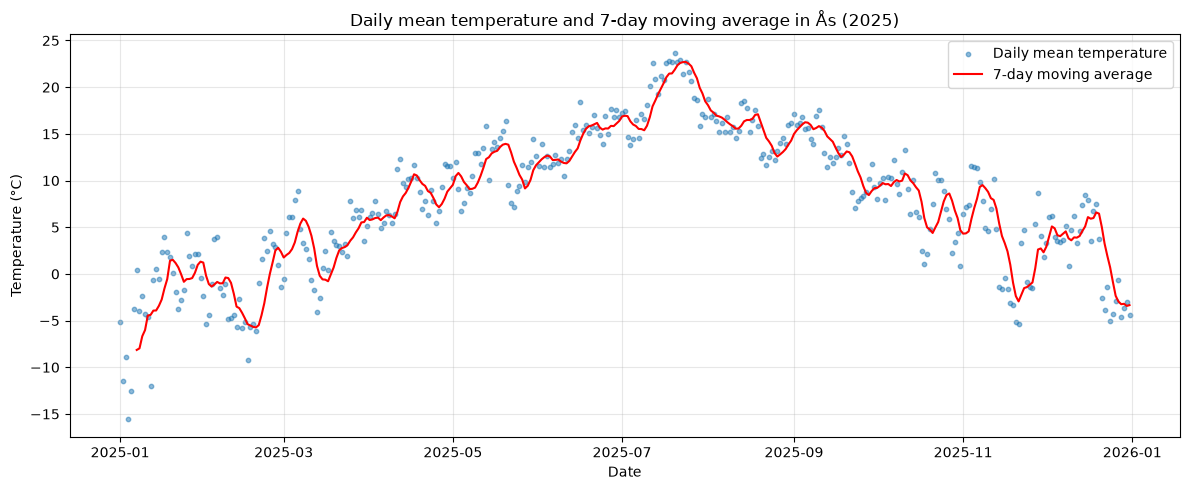

In [68]:
plt.figure(figsize=(12, 5)) #using the same figure size as the plots above 

#daily temperature as small, slightly, transparent points 
plt.scatter(df["date"], df["temperature"], s=10, alpha=0.5, label="Daily mean temperature")
#moving average as a line 
plt.plot(df["date"], df["moving_average"], color="red", label="7-day moving average")

plt.title("Daily mean temperature and 7-day moving average in Ås (2025)")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Results and discussion 
The 7-day moving average out the day to day variation in temperature, so the seasonal pattern becomes clearer: Temperatures rise from January to a peak in July, and fall towards the end of the year. The first few days have no moving average because there are not enough previous days to calculate it. 


## References
- MET Norway. (n.d.). Frost API – Data clarifications. https://frost.met.no/dataclarifications.html.

- MET Norway. (n.d.). How to work with Frost using Python. https://frost.met.no/python_example.html.
